In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc
import seaborn as sns

font = {'size':10}
mpl.rc('font', **font)

### Data_processing to get to df_TEs, T_lims, betas, q_c, q_r and the interaction matrices A

In [1]:
%run Data_processing.py

In [2]:
print(scenarios)

['CurPol_SAP' 'CurPol_OS_1.5C' 'ModAct_OS_1.5C' 'ModAct_OS_1C'
 'ModAct_SAP' 'ssp534-over' 'Neg_SAP' 'GS_NZGHG' 'Ren_NZCO2' 'Neg_NZGHG'
 'Ref_1p5' 'Neg_OS_0C' 'LD_NZGHG' 'SP_NZGHG' 'ssp119']


# Simulations

### Baseline temperature scenario: actual + fitted parameters

In [290]:
baseline = 'CurPol_OS_1.5C'#'ModAct_OS_1.5C'
baseline_disp = baseline#'SSP5-3.4-OS'

if baseline == 'ssp126':
    df_ipcc = pd.read_excel('../../../Data/extendedSSPs.xlsx')
    temp = df_ipcc[df_ipcc['scenario']=='ssp126'].set_index('quantile').iloc[:,9:].transpose()['median'].to_numpy()
else:
    temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,1850+len(temp))-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )

data_folder = '../../../Data/Simulations/Overshoots/%s/OAT'%baseline
# if os.p
if not os.path.isdir(data_folder[:-4]):
    os.mkdir(data_folder[:-4])
if not os.path.isdir(data_folder[:-4]+'/Baseline'):
    os.mkdir(data_folder[:-4]+'/Baseline')
if not os.path.isdir(data_folder):
    os.mkdir(data_folder)
np.savetxt(data_folder[:-4]+'/Baseline/popt.txt',popt)

### Setting up

In [196]:
T_0s = np.arange(0,5.1,step=0.1)
T_peaks = np.arange(0,5.1,step=0.1)
T_oss = np.arange(0,5.1,step=0.1)

t_ups = np.arange(0,201,step=10)
t_plats = np.arange(0,201,step=10)
t_downs = np.arange(0,201,step=10)

pars = [T_0s, T_peaks, T_oss, t_ups, t_plats, t_downs]

years = xdata+t_ref
no_years=len(years)

pcs = [np.ones((len(p),no_years,len(df_TEs)))*q_c.reshape((1,1,len(df_TEs))) for p in pars]
prs = [np.ones((len(p),no_years,len(df_TEs)))*q_r.reshape((1,1,len(df_TEs))) for p in pars]

temps = [np.zeros((len(pars[i]),no_years)) for i in range(len(popt))]
for i in range(len(popt)):
    PAR = np.copy(popt)
    for j,p_j in enumerate(pars[i]):
        PAR[i] = p_j
        temps[i][j,:] = OS_model(xdata,*PAR)
        for t in range(no_years):
            pcs[i][j,t,:] *= temp_response(temps[i][j,t], T_lim, betas)
            prs[i][j,t,:] *= 1-temp_response(temps[i][j,t], T_lim, betas)

In [197]:
%run -i OAT_sensitivity_analysis.py

100%|█████████████████████████████████████████████| 6/6 [08:10<00:00, 81.71s/it]


## Post-simulation analysis

In [198]:
D_noreef = [np.delete(D[i],6,axis=-2) for i in range(len(popt))]
AR_popt = [k_risk(D_noreef[i],1,axis=2)  
           for i in tqdm.tqdm(range(len(popt)))]

D_nr_noint = [np.delete(D_noint[i],6,axis=-2) for i in range(len(popt))]
AR_popt_noint = [k_risk(D_nr_noint[i],1,axis=1) 
                 for i in tqdm.tqdm(range(len(popt)))]

D_nr_baseline = np.delete(D_baseline,6,axis=1)
AR_baseline = k_risk(D_nr_baseline,1,axis=1)

100%|█████████████████████████████████████████████| 6/6 [00:00<00:00, 57.88it/s]


In [199]:
# Saving only 2300 data
data_folder = '../../../Data/Simulations/Overshoots/%s/OAT'%baseline
# if os.p
if not os.path.isdir(data_folder[:-4]):
    os.mkdir(data_folder[:-4])
if not os.path.isdir(data_folder[:-4]+'/Baseline'):
    os.mkdir(data_folder[:-4]+'/Baseline')
if not os.path.isdir(data_folder):
    os.mkdir(data_folder)

par_name = ['temp_init', 'temp_peak', 'temp_stab', 'time_up', 'time_peak', 'time_down']
for i in range(6):
    # FULL OAT: Saving the 2300 tipping risks (EXCLUDING the reefs)
        # shape: len(pars[i]) X no. samples e.g. (51 X 500)
    np.savetxt(data_folder+'/Full_TR_%s.csv'%par_name[i],
               AR_popt[i][:,:,-1]) 
    # FULL OAT: Saving the 2300 individual risk of coral reefs
        # shape: len(pars[i]) X no. samples e.g. (51 X 500)
    np.savetxt(data_folder+'/Full_REEF_%s.csv'%par_name[i],
               D[i][:,:,6,-1])

    # INTERACTIONLESS: Saving the 2300 INDIVIDUAL risks, can turn into AR easily
        # shape: len(pars[i]) X no. TEs e.g. (51 X 9)
    np.savetxt(data_folder+'/Interactionless_IND_%s.csv'%par_name[i],
               D_noint[i][:,:,-1])

# BASELINE: Saving the 2300 individual risks
    # shape: len(pars[i]) X no. TEs e.g. (51 X 9)
np.savetxt(data_folder[:-4]+'/Baseline/interactionMean_indRisk.csv',
           D_baseline.mean(axis=0))

np.savetxt(data_folder[:-4]+'/Baseline/popt.txt',popt)

# Plotting

In [34]:
# Loading saved simulation data
baseline = 'CurPol_OS_1.5C'
data_folder = '../../../Data/Simulations/Overshoots/%s/OAT'%baseline
par_name = ['temp_init', 'temp_peak', 'temp_stab', 'time_up', 'time_peak', 'time_down']
TR = [np.loadtxt(data_folder+'/Full_TR_%s.csv'%par_name[i]) for i in range(6)] # tipping risk (ie aggregate)
D_baseline = np.loadtxt(data_folder[:-4]+'/Baseline/interactionMean_indRisk.csv')
TR_baseline = k_risk(np.delete(np.loadtxt(data_folder[:-4]+'/Baseline/interactionMean_indRisk.csv'),
                               6,axis=0),
                     1,axis=0)
popt = np.loadtxt(data_folder[:-4]+'/Baseline/popt.txt')

# Setting up the range of parameters
T_0s = np.arange(0,5.1,step=0.1)
T_peaks = np.arange(0,5.1,step=0.1)
T_oss = np.arange(0,5.1,step=0.1)

t_ups = np.arange(0,201,step=10)
t_plats = np.arange(0,201,step=10)
t_downs = np.arange(0,201,step=10)

pars = [T_0s, T_peaks, T_oss, t_ups, t_plats, t_downs]

In [35]:
for p,t in zip(par_name,TR):
    print(str(100*t[0,:].mean()) + r'$\pm$' + str(100*t[0,:].std()))

70.88907865931598$\pm$0.8026260977296239
1.579728260488767$\pm$0.0018637436674682642
61.83772679824771$\pm$0.7314672893651736
55.26364919507123$\pm$0.6117307433796846
72.59283618809407$\pm$0.836995126006029
42.771700997854126$\pm$0.3895575620736353


In [37]:
print(D_baseline.shape)

(9, 451)


## Old version using util.plot.Radar etc

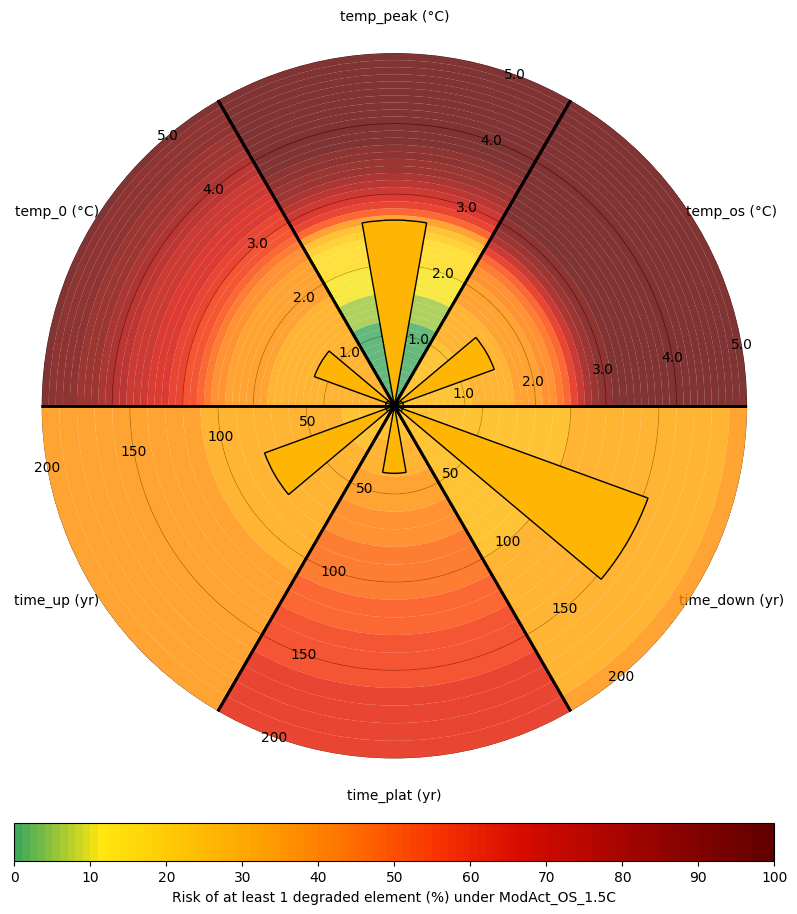

In [10]:
plotting='AR'
# baseline_disp='ssp1-2.6'

titles = ['temp_peak (°C)', 'temp_0 (°C)', 'time_up (yr)', 'time_plat (yr)', 'time_down (yr)', 'temp_os (°C)']
rticks = [np.arange(0,5.1,step=1), np.arange(0,5+.1,step=1),
           np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,201,step=50), np.arange(0,5+.1,step=1)]
ylims=[(0,5), (0,5), (0,200), (0,200), (0,200), (0,5)]
N=len(popt)
outer_width = 360/N
inner_width = 2*180/3/N
width = outer_width+inner_width

fig=plt.figure(figsize=(8,9))
radar = Radar(fig, N, titles=titles, rotate_labels=False, 
              wedge_width = outer_width, with_rlabels=True, 
              ylims=ylims, rticks=rticks,loc_offset=10,wedgetick_lw=2)

sim2ax_reorder = [1,0,3,4,5,2]
AR_popt_reordered = list(map(AR_popt.__getitem__, sim2ax_reorder))
pars_reordered = list(map(pars.__getitem__,sim2ax_reorder))

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)
# bounds = np.arange(-0.5,9,step=1)
# norm = mpl.colors.BoundaryNorm(bounds, cmap.N)

for j, ax, angle, pr, p_val in zip(range(len(popt)), 
                            radar.axes, 
                            radar.angles,
                            pars_reordered,
                            popt[sim2ax_reorder]):
    # to_plot = AR_popt_reordered[j].mean(axis=1).max(axis=1) # Picking out the maximum 1-risk
    if plotting == 'AR':
        to_plot = AR_popt_reordered[j].mean(axis=1)[:,2300-t_ref] # Picking out the final 1-risk
        to_plot_baseline = AR_baseline.mean(axis=0)[2300-t_ref]
    else:
        to_plot = D[sim2ax_reorder[j]].sum(axis=2).mean(axis=1)[:,-1]/9
        to_plot_baseline = D_baseline.sum(axis=1).mean(axis=0)[-1]/9
    radar.wedge_stacked_bar(ax,angle,pr,
                            c_list=c_list,zorder=0,
                            c_vals=to_plot,N_col_bins=20,alpha=0.8,edgecolor=None)
    radar.wedge_stacked_bar(ax,angle,[p_val],
                            c_list=c_list,
                            width=np.deg2rad(inner_width),
                            alpha=1,edgecolor='k',zorder=2,N_col_bins=20,
                            c_vals=[to_plot_baseline])
    
    # popt_en_med = np.median(popts[:,sim2ax_reorder[j]])
    # yerr = np.array([popt_en_med-np.quantile(popts[:,sim2ax_reorder[j]],0.1),
    #                   np.quantile(popts[:,sim2ax_reorder[j]],0.9)-popt_en_med]).reshape(2,1)
    # ax.errorbar(np.deg2rad(angle),popt_en_med, 
    #             yerr=yerr,
    #             c='k',ls='',capsize=7, fmt="x",lw=0.5,capthick=0.5)


radar.draw_wedgeticks(ylims=ylims,width=radar.wedge_width,lw=2)

fig.subplots_adjust(bottom=0.2)
cbar = fig.colorbar(mpl.cm.ScalarMappable(cmap=cmap),
                    ax=radar.axes,orientation='horizontal',
                    fraction=0.1,pad=0.075,label=r'Risk of at least 1 degraded element (%) under '+baseline_disp,alpha=0.8,
                    )
cbar.set_ticks([k for k in np.arange(0,1.1,0.1)],labels=[k for k in range(0,110,10)])

fig.savefig('../../../Figures/Overshoots/NCC/SOS_%s.png'%baseline_disp,bbox_inches='tight')

## Alternative visualisation

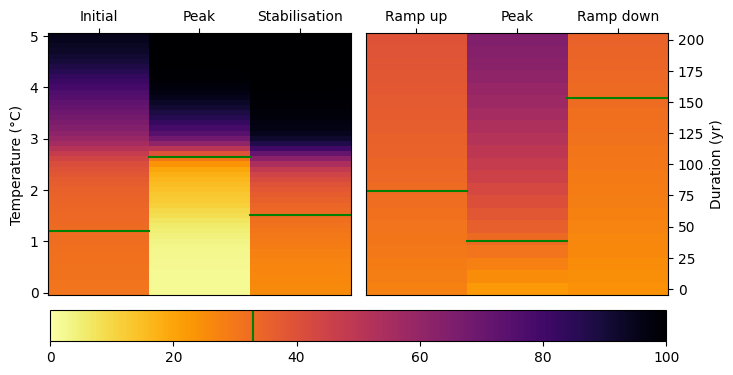

In [11]:
AR_temp = np.array([AR_popt[i] for i in range(3)])
AR_dura = np.array([AR_popt[i] for i in range(3,6)])

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = 'inferno_r'#LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)
baseline_col = 'green'

fig,axs = plt.subplots(ncols=2,figsize=(8,4))
fig.subplots_adjust(wspace=0.05)

for i in range(2):
    axs[i].xaxis.tick_top()
    # axs[i].grid(axis='y')
# axs[0].set_ylim(0,5)
# axs[1].set_ylim(0,200)

axs[0].set_ylabel("Temperature (°C)")
axs[0].set_xticks([0,1,2],[r'Initial', r'Peak', r'Stabilisation'])
axs[0].imshow(100*AR_temp.mean(axis=2)[:,:,2300-t_ref].T,aspect='auto',origin='lower',
                 cmap=cmap,extent=(-0.5, 3-0.5, -.05, T_peaks.max()+0.05),vmin=0,vmax=100)

axs[1].yaxis.tick_right()
axs[1].set_ylabel("Duration (yr)")
axs[1].yaxis.set_label_position("right")
axs[1].set_xticks([0,1,2],[r'Ramp up', r'Peak', r'Ramp down'])
im=axs[1].imshow(100*AR_dura.mean(axis=2)[:,:,2300-t_ref].T,aspect='auto',origin='lower',
                 cmap=cmap,extent=(-0.5, 3-0.5, -5, t_ups.max()+5),vmin=0,vmax=100)
# fig.colorbar()

for i in range(6):
    axs[i//3].plot([i%3-0.5,i%3+0.5],[popt[i]]*2,c=baseline_col)
cb = fig.colorbar(im, ax=axs, orientation='horizontal', fraction=.1,pad=.05)
cb.ax.plot([AR_baseline.mean(axis=0)[-1]*100]*2,[0,1],c=baseline_col)

fig.savefig('../../../Figures/Overshoots/NCC/SOS_alt_%s.png'%baseline,bbox_inches='tight')

# Dev. cells for polar bar chart

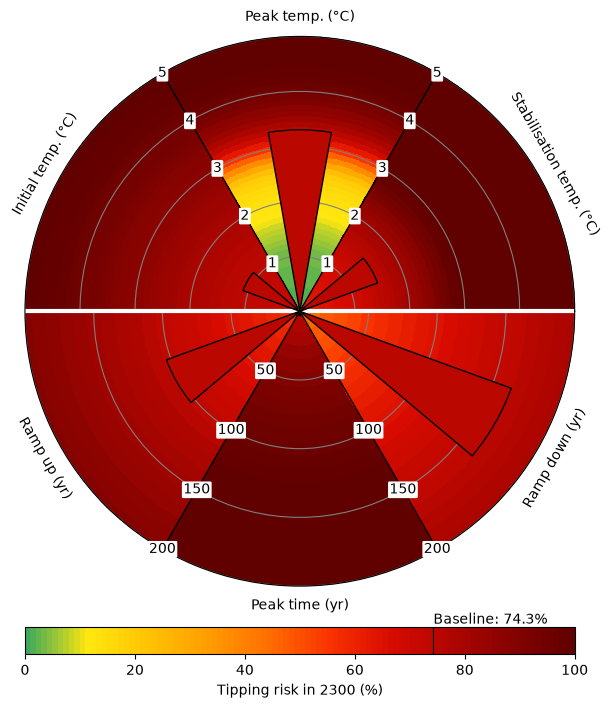

In [8]:
fig, ax = plt.subplots(figsize=(6,7), subplot_kw={'projection': 'polar'},
                        layout='constrained')
labels = ['Stabilisation temp. (°C)', 'Peak temp. (°C)', 'Initial temp. (°C)', 'Ramp up (yr)', 'Peak time (yr)', 'Ramp down (yr)']

N=len(popt)
outer_width = 360/N
inner_width = 2*180/3/N

sim2ax_reorder = [1,0,3,4,5,2]
angles_0 = np.arange(60,421,60)
theta = np.linspace(0,outer_width)

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100)
baseline_col = cmap(TR_baseline[-1])

for i in range(6):
    j = sim2ax_reorder[i]
    to_plot = np.repeat(100*TR[j].mean(axis=-1,keepdims=True), len(theta)-1, axis=1)
    r_diff = np.diff(pars[j])[0]
    r = np.arange(pars[j][0]-r_diff/2,pars[j][-1]+r_diff,r_diff)/pars[j][-1]
    r[0]=0
    im=ax.pcolormesh(np.radians(angles_0[i]+theta), r,
                     to_plot,cmap=cmap,vmin=0,vmax=100)
    ax.bar(np.radians(angles_0[i]+outer_width/2), popt[j]/pars[j][-1], 
           color=baseline_col,
           width=np.radians(inner_width),edgecolor='k',zorder=3)
    
    
ax.set_xticks(np.radians(np.arange(0,360,outer_width)),minor=True)
ax.set_xticks(np.radians(np.arange(30,360,outer_width)),labels)
ax.tick_params(axis='x', which='major')#, pad=10)
labels = []
angles = np.arange(30,360,outer_width)
for label, angle in zip(ax.get_xticklabels(), angles):
    x,y = label.get_position()
    lab = ax.text(x,y, label.get_text(), transform=label.get_transform(),
                  ha=label.get_ha(), va=label.get_va())
    if angle < 180:
        new_angle = angle-90
    else:
        new_angle = angle+90
    lab.set_rotation(new_angle)
    labels.append(lab)
ax.set_xticklabels([])

ax.set_rticks([])
ax.set_rlim(0,1)
ax.grid(axis='x',which='minor',visible=True,lw=1,color='k')
ax.grid(axis='x',which='major',visible=False)


tick_bbox = dict(facecolor='white', 
                 edgecolor='w', 
                 boxstyle='round,pad=0.05')
tick_label_color='k'
# Temperature ticks
temp_ticks = np.arange(1,6,1)/5
for t in temp_ticks:
    ax.plot(np.linspace(0,np.pi),[t]*50,color='gray',lw=0.8,zorder=2)
    for i in range(1,3):
        ax.text(i*np.radians(outer_width),#np.pi*(1/2)-np.radians(inner_width),
                t,round(t*5),color=tick_label_color,
                ha='center',va='center',zorder=3,
                bbox=tick_bbox)

# Time ticks
time_ticks = np.arange(50,201,50)/200
for t in time_ticks:
    ax.plot(np.linspace(np.pi,2*np.pi),[t]*50,color='gray',lw=0.8,zorder=2)
    for i in range(1,3):
        ax.text(np.pi+i*np.radians(outer_width),#np.pi*(3/2)-np.radians(inner_width),
                t,round(t*200),color=tick_label_color,
                ha='center',va='center',zorder=3,
                bbox=tick_bbox)

cb = fig.colorbar(im,orientation='horizontal',label='Tipping risk in 2300 (%)',pad=0)
cb.ax.plot([TR_baseline[-1]*100]*2,[0,1],c='k',lw=0.8)
cb.ax.text(TR_baseline[-1]*100,1,
           'Baseline: '+ str(round(TR_baseline[-1]*100,1))+'%',ha='left',va='bottom')

ax.plot([0]*2,[0,1],color='white',lw=3)
ax.plot([np.pi]*2,[0,1],color='white',lw=3)
fig.savefig('../../../Figures/Overshoots/NCC/SOS_%s.pdf'%baseline,bbox_inches='tight',
            dpi=300,format='pdf')

In [248]:
print(round(TR_baseline[-1]*100,1))

12.0
